# Downloads

## Additional pip installs

This is maily to ensure wandb is setup right, and is able to run in Google Colab

In [ ]:
!pip install wandb -qU

## Importing and Logining into Wandb

In [ ]:
import wandb
wandb.login()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: badri-nandakumar (badri-nandakumar-city-st-georges-university-of-london) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

# Imports

In [ ]:
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

import numpy as np
import random
import time

import torchvision
from torchvision import transforms
import torchvision.transforms.functional as TF
from torchvision.datasets import OxfordIIITPet

import matplotlib.pyplot as plt

# Universal Variables

The main place to control most of the Variables for the entire notebook

## Checking if cuda is avaiable or defaulting to cpu

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Random Seed setting

In [ ]:
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)

In [ ]:
IMG_SIZE = 256
BATCH_SIZE = 128
VAL_SPLIT = 0.20
EPOCHS = 25
LR = 0.001
MOMENTUM = 0.99
WEIGHT_DECAY = 1e-6
PATIENCE = 4
ES_MIN_DELTA = 0.001

NUM_CLASSES = 2

# Loading Dataset

## Class to import dataset

In [ ]:
class oxfordPetDataset(Dataset):
    def __init__(self,root, split="trainval", imgSize=256, augment=False):

        self.dataset = OxfordIIITPet(root, split=split, target_types="segmentation", download=True)
        self.imgSize = imgSize
        self.augment = augment

        self.imgResize = transforms.Resize((imgSize,imgSize), antialias = True)
        self.imgToTensor = transforms.ToTensor()

        self.maskResize = transforms.Resize((imgSize,imgSize), antialias = True, interpolation = transforms.InterpolationMode.NEAREST)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self,idx):
        # Getting image and mask from dataset
        img, mask = self.dataset[idx]

        # Resizing the image and mask as per user inputted size
        img = self.imgResize(img)
        mask = self.maskResize(mask)

        # Simple Augmentation (where 25% to flip horizontally or Vertically)
        if self.augment and random.random() < 0.25:
          img = TF.hflip(img)
          mask = TF.hflip(mask)
        elif self.augment and random.random() >= 0.75:
          img = TF.vflip(img)
          mask = TF.vflip(mask)

        # Converting image to Tensor
        imgTensor = self.imgToTensor(img)

        # Converting mask from numpy to Tensor
        maskNumpy = np.array(mask, dtype=np.int64)
        maskBinary = ((maskNumpy == 1) | (maskNumpy == 3)).astype(np.int64)
        maskTensor = torch.from_numpy(maskBinary)

        return imgTensor, maskTensor

## Actually Loading Dataset

Running the above dataset loading class and storing the information into the opDs variable

In [ ]:
dataRoot = "/content/oxford_pets"
opDs = oxfordPetDataset(root=dataRoot, split="trainval", imgSize=IMG_SIZE, augment=True)
print("Dataset size:", len(opDs))

Dataset size: 3680


## Sample Images and Masks

Printing sample images and masks from the dataset

In [ ]:
def showImgMask(imgTensor, maskTensor):
  img = imgTensor.permute(1,2,0).numpy()
  mask = maskTensor.numpy()

  plt.figure(figsize=(12,4))

  plt.subplot(1,3,1)
  plt.imshow(img)

  plt.subplot(1,3,2)
  plt.imshow(mask)

  plt.subplot(1,3,3)
  plt.imshow(img)
  plt.imshow(mask, alpha=0.3)

  plt.suptitle("Image, Mask, Overlay")
  plt.show()

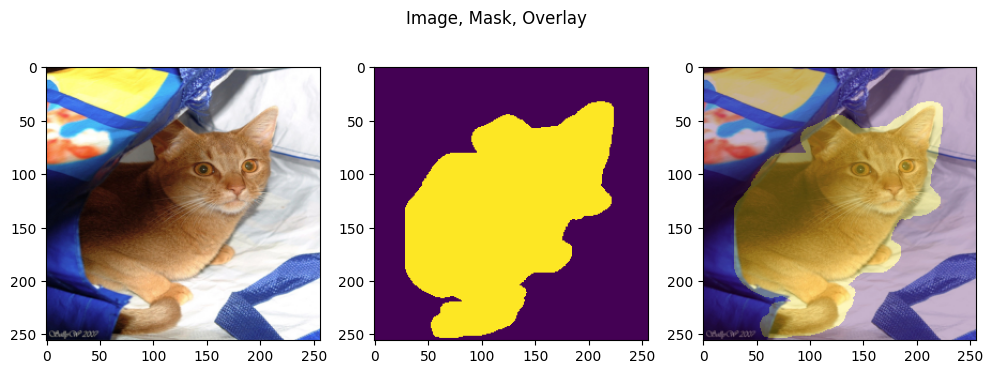

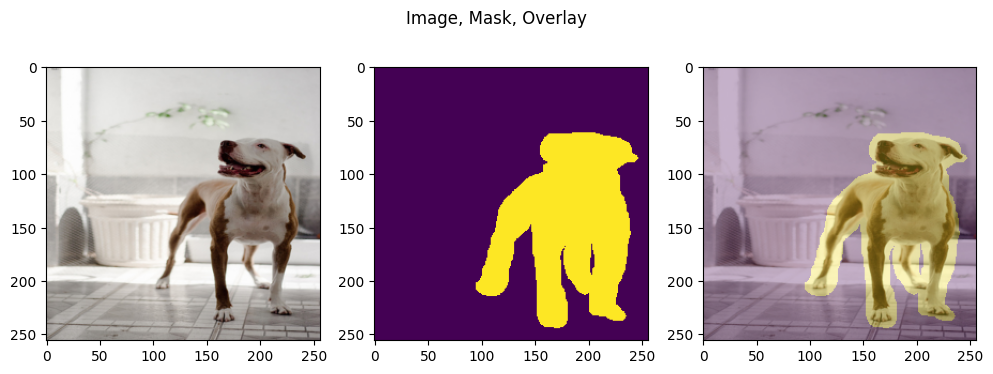

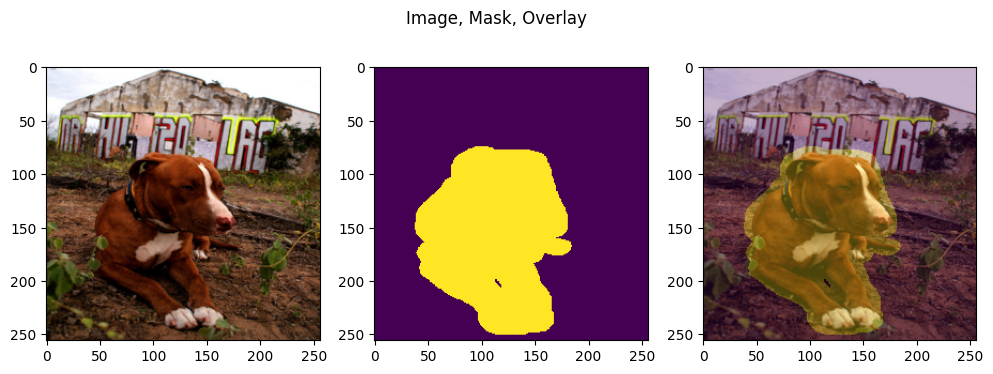

In [ ]:
for i in [0,100,101]:
  imgTensor, maskTensor = opDs[i]
  showImgMask(imgTensor, maskTensor)

## Train Val Splitting

In [ ]:
# Manually Calculating the number of train and validation samples
numVal = int(len(opDs) * VAL_SPLIT)
numTrain = len(opDs) - numVal

train, val = random_split(opDs, [numTrain,numVal],generator=torch.Generator().manual_seed(RANDOM_SEED))
val.dataset.augment = False

trainLoader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
valLoader = DataLoader(val, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

print("Train size:", len(train))
print("Validation size:", len(val))

Train size: 2944
Validation size: 736


# Simple U-Net Implementation

## U-Net Class

In [ ]:
def dConvLayers(inCh,outCh):
    convOperation = nn.Sequential(
        nn.Conv2d(inCh,inCh,kernel_size=3,padding=1),
        nn.BatchNorm2d(inCh),
        nn.ReLU(inplace=True),
        nn.Conv2d(inCh,outCh,kernel_size=3,padding=1),
        nn.BatchNorm2d(outCh),
        nn.ReLU(inplace=True),
        nn.Conv2d(outCh,outCh,kernel_size=3,padding=1),
        nn.BatchNorm2d(outCh),
        nn.ReLU(inplace=True)
    )

    return convOperation

In [ ]:
class specialUNet(nn.Module):
    def __init__(self,numClass):
        super(specialUNet, self).__init__()

        self.maxPool2d = nn.MaxPool2d(kernel_size=2,stride=2)

        self.downConv1 = dConvLayers(3,64)
        self.downConv2 = dConvLayers(64,128)
        self.downConv3 = dConvLayers(128,256)
        self.downConv4 = dConvLayers(256,512)
        self.downConv5 = dConvLayers(512,1024)

        self.downSConv1 = dConvLayers(3,64)
        self.downSConv2 = dConvLayers(64,128)
        self.downSConv3 = dConvLayers(128,256)
        self.downSConv4 = dConvLayers(256,512)

        self.upTrans1 = nn.ConvTranspose2d(in_channels=1024, out_channels=512, kernel_size=2,stride=2)
        self.upTrans2 = nn.ConvTranspose2d(in_channels=512, out_channels=256, kernel_size=2,stride=2)
        self.upTrans3 = nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=2,stride=2)
        self.upTrans4 = nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=2,stride=2)

        self.upConv1 = dConvLayers(1024,512)
        self.upConv2 = dConvLayers(512,256)
        self.upConv3 = dConvLayers(256,128)
        self.upConv4 = dConvLayers(128,64)

        self.outLayer = nn.Conv2d(in_channels=64,out_channels=numClass,kernel_size=1)

    def forward(self,x):
        saveD0 = self.downSConv1(x)

        x = self.downConv1(x)
        x = self.maxPool2d(x)
        saveD1 = self.downSConv2(x)

        x = self.downConv2(x)
        x = self.maxPool2d(x)
        saveD2 = self.downSConv3(x)

        x = self.downConv3(x)
        x = self.maxPool2d(x)
        saveD3 = self.downSConv4(x)

        x = self.downConv4(x)
        x = self.maxPool2d(x)

        x = self.downConv5(x)

        saveU1 = self.upTrans1(x)
        x = self.upConv1(torch.cat([saveD3,saveU1],1))

        saveU2 = self.upTrans2(x)
        x = self.upConv2(torch.cat([saveD2,saveU2],1))

        saveU3 = self.upTrans3(x)
        x = self.upConv3(torch.cat([saveD1,saveU3],1))

        saveU4 = self.upTrans4(x)
        x = self.upConv4(torch.cat([saveD0,saveU4],1))

        return self.outLayer(x)




## Testing Simple U-Net

This is to test if our model is valid from start to finish, and given random input, we are able to get an output of valid size as per number of classes

In [ ]:
inputTestImg = torch.rand((2,3,512,512))
model = specialUNet(numClass=2)
model.to(device) # Move the model to the specified device

total_params = sum(p.numel() for p in model.parameters())
print(total_params)

total_trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(total_trainable_params)

outPut = model(inputTestImg.to(device)) # Also move the test input to the device
print(outPut.shape)

52184310
52184310
torch.Size([2, 2, 512, 512])


# Pixel Accuracy and IoU

Calculating class distribution for cross entropy loss

In [ ]:
# Calculate class distribution
classCounts = torch.zeros(NUM_CLASSES)

for imgs, masks in trainLoader:
    uniqueClasses, counts = masks.unique(return_counts=True)
    for cls, count in zip(uniqueClasses, counts):
        classCounts[int(cls)] += count.item()

print("Class distribution in training masks:")
for i, count in enumerate(classCounts):
    print(f"Class {i}: {count} no. of pixels ({count / classCounts.sum() * 100:.2f}%)")

# Class weights are not directly used by Jaccard Loss, but keeping for informational purposes
if classCounts[0] > 0 and classCounts[1] > 0:
    totalPixels = classCounts.sum()
    classWeights = totalPixels / (NUM_CLASSES * classCounts)
    classWeights = classWeights / classWeights.sum() # Normalize weights
    print(f"Calculated class weights: {classWeights.tolist()}")
else:
    classWeights = torch.ones(NUM_CLASSES)

criterion = nn.CrossEntropyLoss(weight=class_weights)

def pixelAcc(logits, masks):
  preds = logits.argmax(dim=1)
  return (preds == masks).float().mean().item()

def foregroundIOU(logits,masks,fgClass=1):
  preds = logits.argmax(dim=1)
  predsFg = (preds == fgClass).float()
  trueFg  = (masks == fgClass).float()
  intersection = (predsFg * trueFg).sum().item()
  union = (predsFg + trueFg).clamp(0.0, 1.0).sum().item()
  return intersection/(union + 1e-10)

Calculating class distribution:   0%|          | 0/23 [00:00<?, ?it/s]

Class distribution in training masks:
Class 0: 113057488.0 pixels (58.60%)
Class 1: 79880488.0 pixels (41.40%)
Calculated class weights: [0.4140216112136841, 0.5859783887863159]


# Implementing Early Stopping

In [ ]:
class EarlyStopping:
    def __init__(self, patience=2, minDelta=0):

        self.patience = patience
        self.minDelta = minDelta
        self.bestLoss = float('inf')
        self.patienceCounter = 0
        self.earlyStop = False

    def __call__(self, valLoss):
        # if validation loss is less than the best loss, then reset counter
        if valLoss < self.bestLoss - self.minDelta:
            self.bestLoss = valLoss
            self.patienceCounter = 0

        # else increase counter and check if counter has reached the patience treshold
        elif valLoss > self.bestLoss + self.minDelta:
            self.patienceCounter += 1
            if self.patienceCounter >= self.patience:
                self.earlyStop = True
                print(f"No major improvement, early stopping algo triggered!")

        return self.earlyStop

# Training

In [ ]:
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler(enabled=(device.type=="cuda"))

In [ ]:
from logging import log
def perEpoch(loader, train=True):

  model.train(train)

  totalLoss = 0
  totalAcc = 0
  totalIOU = 0
  steps = 0

  for imgs, masks in tqdm(loader):
    imgs = imgs.to(device, non_blocking=True)
    masks = masks.to(device, non_blocking=True)

    with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
      logits = model(imgs)
      loss = criterion(logits, masks)

    if train:
      optimizer.zero_grad(set_to_none=True)
      scaler.scale(loss).backward()
      scaler.step(optimizer)
      scaler.update()

    totalLoss += loss.item()
    totalAcc += pixelAcc(logits.detach(), masks.detach())
    totalIOU += foregroundIOU(logits.detach(), masks.detach(), fgClass=1)
    steps += 1

  return totalLoss/steps, totalAcc/steps, totalIOU/steps

In [ ]:
history = {"trainLoss":[], "valLoss":[],"trainAcc":[],"valAcc":[],"trainIOU":[],"valIOU":[]}

In [ ]:
run = wandb.init(
    entity="badri-nandakumar-city-st-georges-university-of-london",
    project="u-net-runs",
    name=f"special-unet-{EPOCHS}",

    config={
        "IMG_SIZE": IMG_SIZE,
        "BATCH_SIZE": BATCH_SIZE,
        "VAL_SPLIT": VAL_SPLIT,
        "EPOCHS": EPOCHS,
        "LR": LR,
        "MOMENTUM": MOMENTUM,
        "WEIGHT_DECAY":WEIGHT_DECAY,

        "PATIENCE": PATIENCE,
        "ES_MIN_DELTA": ES_MIN_DELTA,

        "optimizer": "AdamW",
        "scheduler": "None",
        "criterion": "CrossEntropyLoss",

        "architecture": "Special U-Net",
        "dataset": "Oxford Pets",
        "Train-Loss":history["trainLoss"],
        "Val-Loss":history["valLoss"],
        "Train-Acc":history["trainAcc"],
        "Val-Acc":history["valAcc"],
        "Train-IOU":history["trainIOU"],
        "Val-IOU":history["valIOU"],
    },
)


In [ ]:
start = time.time()

# Initialize EarlyStopping
earlyStopping = EarlyStopping(patience=PATIENCE, minDelta=ES_MIN_DELTA)

for epoch in range(1,EPOCHS+1):
  # Running training logic
  trainLoss, trainAcc, trainIOU = perEpoch(trainLoader,train=True)
  valLoss, valAcc, valIOU = perEpoch(valLoader,train=False)

  # Updating Loss, Accuracy and IOU values
  history["trainLoss"].append(trainLoss)
  history["valLoss"].append(valLoss)

  history["trainAcc"].append(trainAcc)
  history["valAcc"].append(valAcc)

  history["trainIOU"].append(trainIOU)
  history["valIOU"].append(valIOU)

  # Logging the values with wandb
  run.log({
      "train_loss": trainLoss, "train_acc": trainAcc, "train_iou": trainIOU,
      "val_loss": valLoss, "val_acc": valAcc, "val_iou": valIOU,
      "epoch": epoch
  })

  print(f"Epoch {epoch:02d}/{EPOCHS} |"
        f"Train Loss: {trainLoss:.3f} Acc: {trainAcc:.3f} IOU: {trainIOU:.3f} |"
        f"Val Loss: {valLoss:.3f} Acc: {valAcc:.3f} IOU: {valIOU:.3f} ")

  # Check for early stopping
  if earlyStopping(valLoss):
      print(f"Stopping training early at epoch {epoch}")
      break

# Cleaning up the wandb items
run.finish()
print("Training Time (Mins):",(time.time()-start)/60)

  0%|          | 0/23 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

Epoch 01/25 |Train Loss: 0.603 Acc: 0.655 IOU: 0.465 |Val Loss: 5.491 Acc: 0.573 IOU: 0.480 


  0%|          | 0/23 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

Epoch 02/25 |Train Loss: 0.461 Acc: 0.787 IOU: 0.604 |Val Loss: 0.755 Acc: 0.731 IOU: 0.557 


... (67 outputs left out)

  0%|          | 0/6 [00:00<?, ?it/s]

Epoch 25/25 |Train Loss: 0.164 Acc: 0.933 IOU: 0.852 |Val Loss: 0.226 Acc: 0.913 IOU: 0.816 


epoch,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
train_acc,▁▄▅▅▆▆▆▆▇▇▇▇▇▇▇▇█████████
train_iou,▁▄▄▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇███████
train_loss,█▆▅▅▄▄▄▃▃▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁
val_acc,▁▄▄▂▃▆▇▇▇▇▇▇▆▇▅██▇███████
val_iou,▁▃▃▂▃▅▆▆▆▆▅▆▆▆▄▇▇▇█▇▇████
val_loss,█▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,25
train_acc,0.93287
train_iou,0.85242
train_loss,0.16388


Training Time (Mins): 12.840108315149942


## Loss plotting

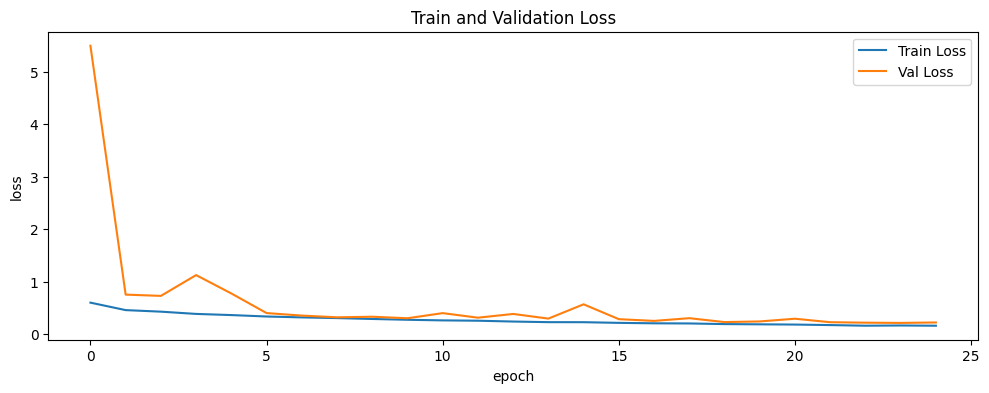

In [ ]:
plt.figure(figsize=(12,4))
plt.plot(history["trainLoss"], label="Train Loss")
plt.plot(history["valLoss"], label="Val Loss")
plt.legend()
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Train and Validation Loss")
plt.show()

# Sample Prediction and Visualisation

In [ ]:
@torch.no_grad()
def predict(imgTensor):
  model.eval()
  x = imgTensor.unsqueeze(0).to(device)
  logits = model(x)[0].cpu()
  return logits.argmax(dim=0)

def showPreds(imgTensor, maskTensor, predTensor,title=""):
  img = imgTensor.permute(1,2,0).cpu().numpy()
  mask = maskTensor.cpu().numpy()
  pred = predTensor.cpu().numpy()

  plt.figure(figsize = (12,4))

  plt.subplot(1,4,1)
  plt.imshow(img)
  plt.axis("off")
  plt.title("Image")

  plt.subplot(1,4,2)
  plt.imshow(mask)
  plt.axis("off")
  plt.title("Mask")

  plt.subplot(1,4,3)
  plt.imshow(pred)
  plt.axis("off")
  plt.title("Predicted Mask")

  plt.subplot(1,4,4)
  plt.imshow(img)
  plt.imshow(pred,alpha=0.4)
  plt.axis("off")
  plt.title("Overlay of Predicted")

  plt.suptitle(title)
  plt.show()

In [ ]:
for i in range(0,101,10):
  imgTensor, maskTensor = val[i]
  predTensor = predict(imgTensor)
  showPreds(imgTensor, maskTensor, predTensor, title=f"Validation Sample {i}")

Output hidden; open in https://colab.research.google.com to view.

# Saving Model and Weights

In [ ]:
savePath = "/content/drive/MyDrive/Image_Processing/Runs Model and Weights Folder/special-u-net-"+str(EPOCHS)+"-Epoch.pth"
torch.save(model.state_dict(),savePath)